# 08 · MCU temperature-sensor calibration

**Goal:** predict each MCU chip's temperature-sensor reading at **110 °C** (the *hot point*, `TS_CAL2`) from data the
tester already has at room temperature, so most chips can skip the slow hot insertion.

- Every chip's sensor is read at **30 °C** (`TS_CAL1`, fused into the chip). Firmware converts readings to °C with a
  two-point line through the 30 °C and 110 °C values, so an error in the hot point becomes a temperature error.
- In this dataset **only MCU-C measures the hot point on the tester**. The task (from the dataset's README): *train
  there and predict for MCU-A and MCU-B*. Their true hot points exist in the synthetic data and are used **only to
  score** the predictions.
- **Score:** the temperature the chip would report when it is really at 110 °C, calibrated with the predicted hot
  point, minus 110 °C. All data is synthetic.

In [1]:
import glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
TEAL, COPPER, GREY = "#0f766e", "#b4501e", "#857a69"


def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None


path = find("mcu_trim_fuse.csv")
if path is None:
    from google.colab import files  # in Colab: upload mcu_trim_fuse.csv
    files.upload()
    path = "mcu_trim_fuse.csv"
mcu = pd.read_csv(path)
mcu["rise_counts"] = mcu.ts_cal2_110C_counts - mcu.ts_cal1_30C_counts  # counts gained from 30 to 110 C
mcu.groupby("derivative").agg(chips=("die_id", "size"), wafers=("wafer_id", "nunique"),
                              hot_point_measured=("ts_cal2_measured_on_tester", "mean"),
                              rise_mean=("rise_counts", "mean"), rise_std=("rise_counts", "std")).round(2)

,chips,wafers,hot_point_measured,rise_mean,rise_std
derivative,,,,,
MCU-A,6315,15,0.0,258.80,4.36
MCU-B,1263,3,0.0,257.44,4.61
MCU-C,842,2,1.0,249.29,3.61


MCU-C (measured) gains about 249 counts from 30 to 110 °C; MCU-A and MCU-B gain about 258. The sensor slope
depends on the **process**, and the three versions were made with different process conditions, so one fixed slope
from MCU-C would be biased for the others.

In [2]:
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]
FEATURES = ["ts_cal1_30C_counts"] + PCM + POS
train = mcu[mcu.ts_cal2_measured_on_tester].reset_index(drop=True)   # MCU-C: hot point measured
target = mcu[~mcu.ts_cal2_measured_on_tester].reset_index(drop=True)  # MCU-A / MCU-B: never measured hot


def temp_error_C(rise_pred, df):
    """Reported temperature at a true 110 C, two-point calibration with the predicted hot point, minus 110 C."""
    return 30 + df.rise_counts * 80 / rise_pred - 110


print(f"train (MCU-C): {len(train)} chips / {train.wafer_id.nunique()} wafers · "
      f"predict for MCU-A/B: {len(target)} chips / {target.wafer_id.nunique()} wafers")
mcu[PCM + ["rise_counts"]].corr()["rise_counts"].drop("rise_counts").round(3)

train (MCU-C): 842 chips / 2 wafers · predict for MCU-A/B: 7578 chips / 18 wafers


pcm_vth_n_mV       -0.186
pcm_vth_p_mV       -0.019
pcm_rs_ohm_sq      -0.401
pcm_tox_A           0.773
pcm_mobility_rel   -0.208
Name: rise_counts, dtype: float64

## 1 · Baseline and models
**Baseline:** today's simplest choice, one fixed rise for every chip (the MCU-C average). Then Ridge, Random Forest and
gradient boosting on the 30 °C reading, the process monitors and the die position.

In [3]:
def score(name, rise_pred):
    e = temp_error_C(rise_pred, target)
    row = {"method": name, "MAE (°C)": np.abs(e).mean(), "worst (°C)": np.abs(e).max(),
           "within ±1 °C %": (np.abs(e) <= 1).mean() * 100, "within ±2 °C %": (np.abs(e) <= 2).mean() * 100}
    for d in ("MCU-A", "MCU-B"):
        row[f"MAE {d}"] = np.abs(e[target.derivative == d]).mean()
    return row


models = {"Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
          "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
          "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED)}
rows = [score("Fixed rise (baseline)", np.full(len(target), train.rise_counts.mean()))]
for name, m in models.items():
    rows.append(score(name, m.fit(train[FEATURES], train.rise_counts).predict(target[FEATURES])))
results = pd.DataFrame(rows).round(3)
results

,method,MAE (°C),worst (°C),within ±1 °C %,within ±2 °C %,MAE MCU-A,MAE MCU-B
0,Fixed rise (baseline),2.998,8.572,8.511,24.571,3.066,2.658
1,Ridge,0.820,3.932,66.825,95.091,0.821,0.814
2,Random Forest,1.485,6.540,38.387,71.668,1.521,1.305
3,HistGradientBoosting,1.758,6.712,30.443,61.441,1.800,1.546


**Ridge wins clearly.** The slope follows the process monitors (mostly oxide thickness) almost linearly, and
MCU-A/B sit at different process values than MCU-C. A straight line **extrapolates** to them; tree models cannot go
beyond the values they were trained on, so they stay close to MCU-C's slope and do worse.

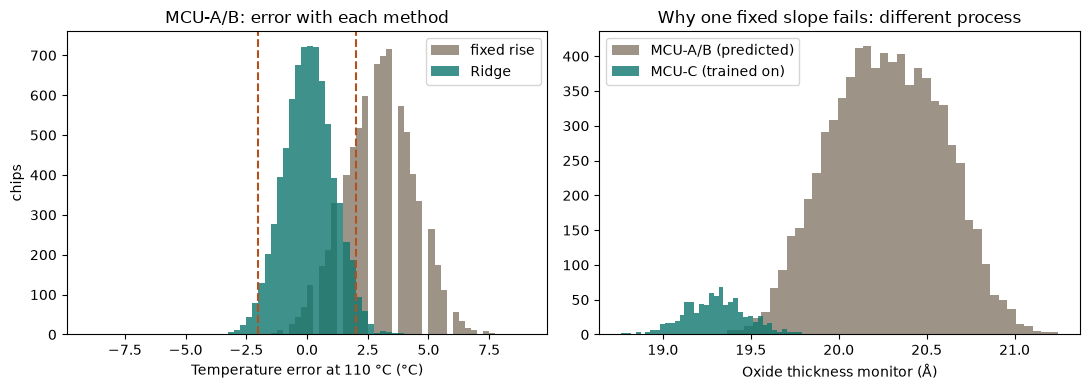

MCU-A/B chips outside MCU-C's oxide-thickness range: 89% (the model extrapolates for these)


In [4]:
ridge = models["Ridge"].fit(train[FEATURES], train.rise_counts)
err = temp_error_C(ridge.predict(target[FEATURES]), target)
base = temp_error_C(np.full(len(target), train.rise_counts.mean()), target)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(-9, 9, 73)
ax[0].hist(base, bins=bins, color=GREY, alpha=.8, label="fixed rise")
ax[0].hist(err, bins=bins, color=TEAL, alpha=.8, label="Ridge")
for x in (-2, 2):
    ax[0].axvline(x, color=COPPER, ls="--")
ax[0].set(xlabel="Temperature error at 110 °C (°C)", ylabel="chips", title="MCU-A/B: error with each method")
ax[0].legend()
tox = train.pcm_tox_A
ax[1].hist(target.pcm_tox_A, bins=40, color=GREY, alpha=.8, label="MCU-A/B (predicted)")
ax[1].hist(tox, bins=40, color=TEAL, alpha=.8, label="MCU-C (trained on)")
ax[1].set(xlabel="Oxide thickness monitor (Å)", title="Why one fixed slope fails: different process"); ax[1].legend()
plt.tight_layout(); plt.show()
outside = ((target.pcm_tox_A < tox.min()) | (target.pcm_tox_A > tox.max())).mean() * 100
print(f"MCU-A/B chips outside MCU-C's oxide-thickness range: {outside:.0f}% (the model extrapolates for these)")

## 2 · Every MCU-A/B wafer separately
The model is trained once on MCU-C and scored on each of the 18 MCU-A/B wafers.

In [5]:
per_wafer = (pd.DataFrame({"wafer": target.wafer_id, "derivative": target.derivative, "abs_err": np.abs(err)})
             .groupby(["derivative", "wafer"]).abs_err.agg(MAE_C="mean", worst_C="max").reset_index())
print(f"MAE per wafer: median {per_wafer.MAE_C.median():.2f} °C, range {per_wafer.MAE_C.min():.2f}-"
      f"{per_wafer.MAE_C.max():.2f} °C over {len(per_wafer)} wafers")
per_wafer.round(2)

MAE per wafer: median 0.82 °C, range 0.78-0.87 °C over 18 wafers


,derivative,wafer,MAE_C,worst_C
0,MCU-A,MA1-W01,0.81,3.29
1,MCU-A,MA1-W02,0.81,3.21
2,MCU-A,MA1-W03,0.80,3.79
3,MCU-A,MA1-W04,0.82,3.80
4,MCU-A,MA1-W05,0.85,3.62
5,MCU-A,MA2-W01,0.81,2.44
6,MCU-A,MA2-W02,0.84,3.01
7,MCU-A,MA2-W03,0.82,3.19
8,MCU-A,MA2-W04,0.83,3.43
9,MCU-A,MA2-W05,0.79,2.93


## 3 · Inside MCU-C only
With only two MCU-C wafers, each is held out in turn. Inside one product the process barely varies, so the model can
only match the fixed rise: the gain above comes from **moving across product versions**, not from extra precision
within one.

In [6]:
rows = []
for w in sorted(train.wafer_id.unique()):
    a, b = train[train.wafer_id != w], train[train.wafer_id == w]
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(a[FEATURES], a.rise_counts)
    rows.append({"held-out MCU-C wafer": w, "Ridge MAE (°C)": np.abs(temp_error_C(m.predict(b[FEATURES]), b)).mean(),
                 "fixed rise MAE (°C)": np.abs(temp_error_C(np.full(len(b), a.rise_counts.mean()), b)).mean()})
pd.DataFrame(rows).round(3)

,held-out MCU-C wafer,Ridge MAE (°C),fixed rise MAE (°C)
0,MC1-W01,0.912,0.950
1,MC1-W02,0.946,0.964


## 4 · Save the model
Saved as `tsense_models.joblib`; the website loads it as is.

In [7]:
t0 = time.perf_counter(); ridge.predict(target[FEATURES]); per_chip_ms = (time.perf_counter() - t0) / len(target) * 1000
r = results.set_index("method")
bundle = {
    "model": ridge, "features": FEATURES, "target": "rise_counts (ts_cal2_110C_counts - ts_cal1_30C_counts)",
    "metrics": {"mae_C": float(r.loc["Ridge", "MAE (°C)"]), "worst_C": float(r.loc["Ridge", "worst (°C)"]),
                "within1_pct": float(r.loc["Ridge", "within ±1 °C %"]),
                "within2_pct": float(r.loc["Ridge", "within ±2 °C %"]),
                "baseline_mae_C": float(r.loc["Fixed rise (baseline)", "MAE (°C)"]),
                "baseline_within2_pct": float(r.loc["Fixed rise (baseline)", "within ±2 °C %"]),
                "chips": int(len(target)), "wafers": int(per_wafer.shape[0]),
                "wafer_mae_min_C": float(per_wafer.MAE_C.min()), "wafer_mae_max_C": float(per_wafer.MAE_C.max()),
                "outside_train_tox_pct": float(outside), "per_chip_ms": float(per_chip_ms)},
}
joblib.dump(bundle, "tsense_models.joblib", compress=3)
json.dumps(bundle["metrics"], indent=1)

'{\n "mae_C": 0.82,\n "worst_C": 3.932,\n "within1_pct": 66.825,\n "within2_pct": 95.091,\n "baseline_mae_C": 2.998,\n "baseline_within2_pct": 24.571,\n "chips": 7578,\n "wafers": 18,\n "wafer_mae_min_C": 0.7839393694739168,\n "wafer_mae_max_C": 0.8673196751251507,\n "outside_train_tox_pct": 88.84930060702033,\n "per_chip_ms": 0.00038995777691109066\n}'

## Conclusion
- Trained only on MCU-C (the one version whose hot point is measured), **Ridge predicts the 110 °C calibration point of
  MCU-A and MCU-B with a typical temperature error of about 0.8 °C**, against about 3 °C for one fixed slope. About 95%
  of chips land within ±2 °C.
- The gain comes from the process monitors: they let a straight-line model carry the slope across product versions.
  Tree models cannot extrapolate and do worse.
- **What it is for:** skipping the hot insertion for products whose temperature spec allows the predicted accuracy,
  with a small sample still measured hot to monitor the model.
- **Limits:** synthetic data; most MCU-A/B chips lie outside MCU-C's process range, so the model extrapolates and a
  real flow would confirm it on a measured sample of each new version first.